# 5. Energy drift — `fp32` leaks, and Euler is not even close

**The lie.** *"Smaller `dt` or more bits makes any integrator fine."*

A harmonic oscillator has constant energy `E = ½(v² + x²)`. Watch three
integrators in double precision, then watch symplectic Verlet accumulate drift
when you drop to float32.

## The setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams["figure.dpi"] = 110
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

In [2]:
def euler(dt, n, dtype):
    x, v = dtype(1.0), dtype(0.0)
    E = np.empty(n, dtype=np.float64)
    for i in range(n):
        E[i] = float(x) ** 2 / 2 + float(v) ** 2 / 2
        x, v = x + dt * v, v - dt * x
    return E

def rk4(dt, n, dtype):
    x, v = dtype(1.0), dtype(0.0)
    E = np.empty(n, dtype=np.float64)
    for i in range(n):
        E[i] = float(x) ** 2 / 2 + float(v) ** 2 / 2
        k1x, k1v = v, -x
        k2x, k2v = v + dt/2*k1v, -(x + dt/2*k1x)
        k3x, k3v = v + dt/2*k2v, -(x + dt/2*k2x)
        k4x, k4v = v + dt*k3v,   -(x + dt*k3x)
        x = x + dt/6*(k1x + 2*k2x + 2*k3x + k4x)
        v = v + dt/6*(k1v + 2*k2v + 2*k3v + k4v)
    return E

def verlet(dt, n, dtype):
    x, v = dtype(1.0), dtype(0.0)
    E = np.empty(n, dtype=np.float64)
    a = -x
    for i in range(n):
        E[i] = float(x) ** 2 / 2 + float(v) ** 2 / 2
        v_half = v + dt/2 * a
        x = x + dt * v_half
        a = -x
        v = v_half + dt/2 * a
    return E

## The reality

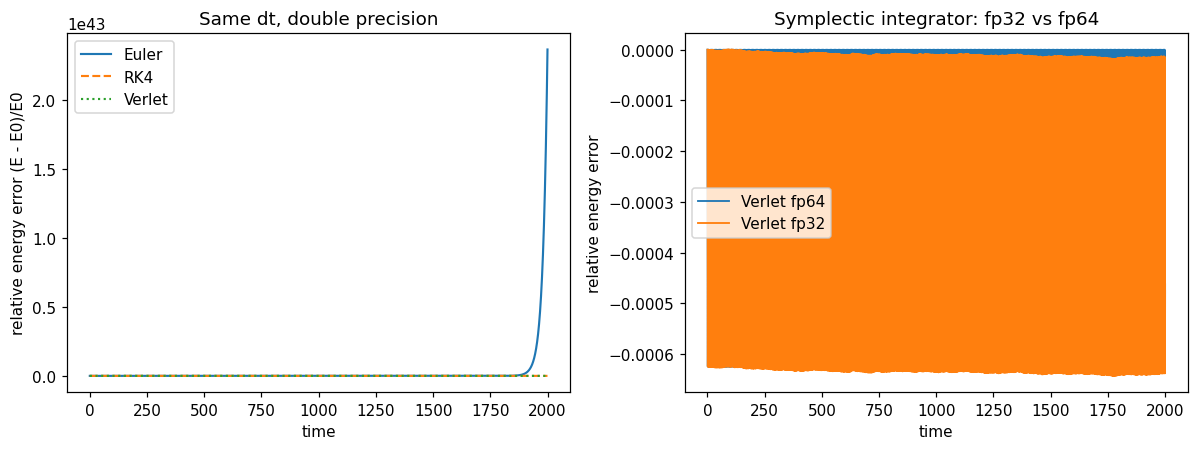

Euler   final |drift| = 2.367e+43   max |drift| = 2.367e+43
RK4     final |drift| = 8.678e-06   max |drift| = 8.678e-06
Verlet  final |drift| = 4.627e-04   max |drift| = 6.250e-04


In [3]:
dt, n = 0.05, 40000
E0 = 0.5

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

for name, fn, style in [("Euler", euler, "-"), ("RK4", rk4, "--"), ("Verlet", verlet, ":")]:
    E = fn(dt, n, np.float64)
    ax[0].plot(np.arange(n) * dt, (E - E0) / E0, style, lw=1.4, label=name)

ax[0].set_xlabel("time")
ax[0].set_ylabel("relative energy error (E - E0)/E0")
ax[0].set_title("Same dt, double precision")
ax[0].legend()

for name, fn, style in [("Verlet fp64", np.float64, "-"), ("Verlet fp32", np.float32, "-")]:
    E = verlet(dt, n, fn)
    ax[1].plot(np.arange(n) * dt, (E - E0) / E0, style, lw=1.2, label=name)

ax[1].set_xlabel("time")
ax[1].set_ylabel("relative energy error")
ax[1].set_title("Symplectic integrator: fp32 vs fp64")
ax[1].legend()

fig.tight_layout()
fig.savefig(FIG / "05_energy_drift.png", bbox_inches="tight")
plt.show()

for name, fn in [("Euler", euler), ("RK4", rk4), ("Verlet", verlet)]:
    e = (fn(dt, n, np.float64) - E0) / E0
    print(f"{name:7s} final |drift| = {abs(e[-1]):.3e}   max |drift| = {abs(e).max():.3e}")

## The rule

- **Explicit Euler is unconditionally wrong for Hamiltonian systems** — energy
  grows without bound. It is not a "small dt" problem.
- **Symplectic methods (Verlet / leapfrog / Störmer) keep energy bounded** — it
  oscillates but does not drift, because they preserve the geometry.
- Precision is separate from *method*: symplectic + float32 still beats
  non-symplectic + float64 for long-time energy behaviour, but accumulate enough
  steps and float32's coarser rounding shows up as slow drift. Choose the method
  for structure, the precision for duration.

## Taking it further

- Hairer, Lubich & Wanner, *Geometric Numerical Integration* — why symplectic.
- Leapfrog/Verlet is the default for molecular dynamics; forward Euler never is.
- This is the numerical-analysis face of "structure-preserving algorithms."